In [1]:
import pandas as pd
import sqlite3
import json
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
# Подключение к базе (путь относительно notebooks/)
conn = sqlite3.connect('../data/prices.db')
df = pd.read_sql("""
    SELECT article, name, sizes_json, sizes_count
    FROM prices
    WHERE date = (SELECT MAX(date) FROM prices)
    AND sizes_json IS NOT NULL
""", conn)
conn.close()

In [7]:
df.head()

,article,name,sizes_json,sizes_count
0,1822992862,"Флисовый комбинезон для девочки, демисезон","[{""size"": ""98-104"", ""product"": 1569.0, ""basic""...",5
1,1522101297,"Флисовый комбинезон для девочки, демисезон","[{""size"": ""104"", ""product"": 1569.0, ""basic"": 2...",4
2,1708452295,"Шапка на липучке флисовая для для девочки, дем...","[{""size"": ""42-44"", ""product"": 702.0, ""basic"": ...",3
3,1479148394,Флисовая кофта на молнии для девочки,"[{""size"": ""104"", ""product"": 1629.0, ""basic"": 2...",5
4,1822992944,Демисезонный флисовый комбинезон для мальчика,"[{""size"": ""104"", ""product"": 1569.0, ""basic"": 2...",5


In [8]:
print(f"Товаров с размерами: {len(df)}")

Товаров с размерами: 2597


In [10]:
# Разворачиваем JSON в длинный формат: одна строка = один размер
rows = []
for _, row in df.iterrows():
    try:
        sizes = json.loads(row['sizes_json'])
    except (json.JSONDecodeError, TypeError):
        continue
    for s in sizes:
        if s.get('product'):
            rows.append({
                'article': row['article'],
                'name': row['name'],
                'size': s['size'],
                'price': s['product'],
                'basic': s['basic'],
            })

sizes_df = pd.DataFrame(rows)
print(f"Строк с размерами: {len(sizes_df)}")
print(sizes_df.head())

Строк с размерами: 9286
      article                                        name    size   price  \
0  1822992862  Флисовый комбинезон для девочки, демисезон  98-104  1569.0   
1  1822992862  Флисовый комбинезон для девочки, демисезон     104  1569.0   
2  1822992862  Флисовый комбинезон для девочки, демисезон     110  1569.0   
3  1822992862  Флисовый комбинезон для девочки, демисезон     116  1569.0   
4  1822992862  Флисовый комбинезон для девочки, демисезон     122  1569.0   

    basic  
0  2649.0  
1  2649.0  
2  2649.0  
3  2649.0  
4  2649.0  


In [29]:
sizes_df.groupby('article').agg({'price': 'value_counts'})

,,price
article,price,
1000869373,1231.0,5
1000869383,1335.0,5
1000919746,808.0,5
1000919799,808.0,5
1001206559,2182.0,6
...,...,...
998012492,1962.0,4
998080544,1086.0,8
998080545,1086.0,8


In [30]:
# Для каждого товара: сколько уникальных цен среди размеров
price_variation = sizes_df.groupby('article')['price'].nunique()

print(f"Товаров с одинаковой ценой по всем размерам: {(price_variation == 1).sum()}")
print(f"Товаров с разными ценами: {(price_variation > 1).sum()}")
print(f"Доля товаров с разными ценами: {(price_variation > 1).mean() * 100:.1f}%")

# Разница для тех, у кого она есть
price_range = sizes_df.groupby('article')['price'].agg(['min', 'max'])
price_range['diff_pct'] = (price_range['max'] - price_range['min']) / price_range['min'] * 100

diff_only = price_range[price_range['diff_pct'] > 0]['diff_pct']
if len(diff_only) > 0:
    print(f"\nРазница по размерам (только товары с разными ценами):")
    print(f"  Медиана: {diff_only.median():.1f}%")
    print(f"  Среднее: {diff_only.mean():.1f}%")
    print(f"  Максимум: {diff_only.max():.1f}%")
else:
    print("\nНет товаров с разными ценами по размерам")

Товаров с одинаковой ценой по всем размерам: 2286
Товаров с разными ценами: 17
Доля товаров с разными ценами: 0.7%

Разница по размерам (только товары с разными ценами):
  Медиана: 13.0%
  Среднее: 12.7%
  Максимум: 13.1%


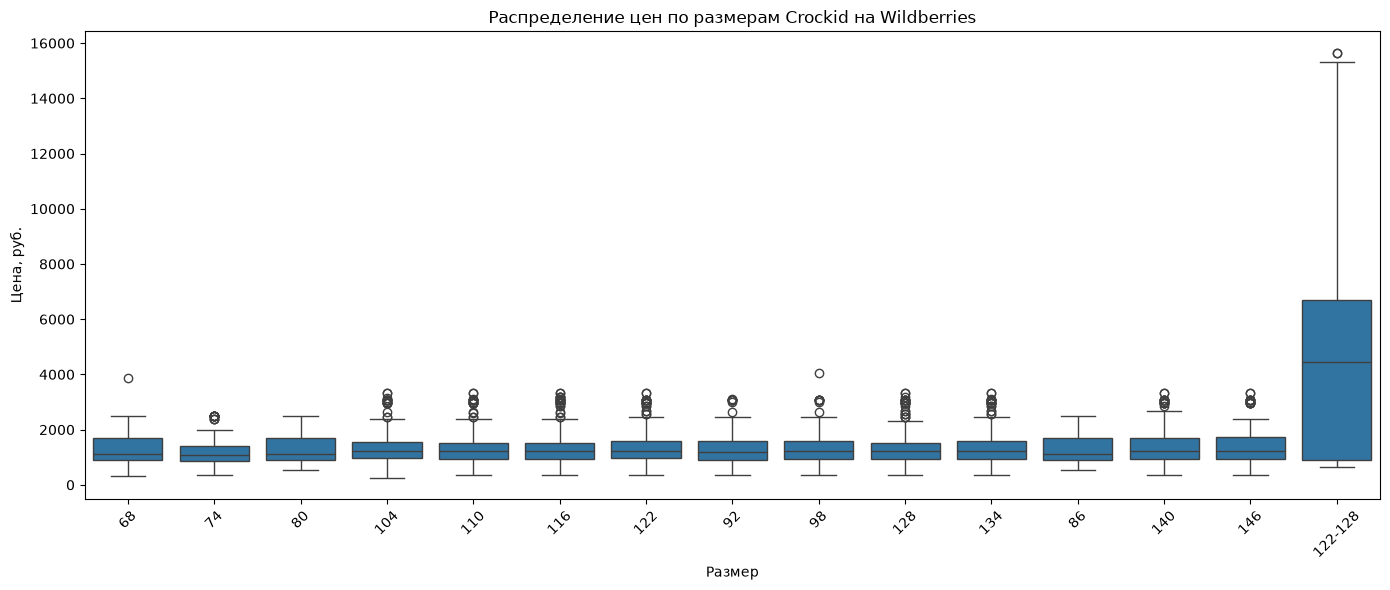

In [35]:
# Топ-15 самых частых размеров
top_sizes = sizes_df['size'].value_counts().head(15).index

plt.figure(figsize=(14, 6))
sns.boxplot(data=sizes_df[sizes_df['size'].isin(top_sizes)], x='size', y='price')
plt.title('Распределение цен по размерам Crockid на Wildberries')
plt.xlabel('Размер')
plt.ylabel('Цена, руб.')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
# Топ-10 товаров с самой большой разницей
top_diff = price_range.nlargest(10, 'diff_pct').reset_index()
top_diff = top_diff.merge(df[['article', 'name']], on='article')
print(top_diff[['name', 'min', 'max', 'diff_pct']])

                                                name     min     max  \
0             Брюки из флиса на резинке для мальчика   659.0   745.0   
1                             Брюки флисовые детские   829.0   937.0   
2                   Флисовый комбинезон для мальчика  1666.0  1883.0   
3  Детское мембранное пальто с утеплителем, демис...  4484.0  5068.0   
4                     Свитшот из хлопка для мальчика  1106.0  1250.0   
5                 Школьные штаны для девочки, хлопок  1736.0  1962.0   
6              Трикотажное детское платье, с принтом  1314.0  1485.0   
7                Зимнее пальто для девочки, мембрана  6158.0  6959.0   
8                Перчатки демисезонные детские, флис   708.0   800.0   
9          Хлопковые штаны со стрелками для мальчика  1578.0  1783.0   

    diff_pct  
0  13.050076  
1  13.027744  
2  13.025210  
3  13.024086  
4  13.019892  
5  13.018433  
6  13.013699  
7  13.007470  
8  12.994350  
9  12.991128  
